# Actividad Individual 2 — EDA básico
**Análisis de Datos · CEIA FIUBA · 5B 2026**
**Alumno:** Leonardo Barahona
**Dataset:** Coffee Quality Database (Coffee Quality Institute) — vía [TidyTuesday 2020-07-07](https://github.com/rfordatascience/tidytuesday/tree/master/data/2020/2020-07-07)

### Objetivo
Realizar un EDA básico: tipos de variables, estadística descriptiva, relaciones entre variables y al menos 3 gráficos distintos.

### Preguntas guía
1. ¿Cómo se distribuye la calidad del café (puntaje total de cata)?
2. ¿Qué atributos sensoriales están más relacionados con el puntaje total?
3. ¿La altitud se relaciona con la calidad?
4. ¿Cómo se compara Honduras con el resto de Centroamérica?
5. ¿El método de procesamiento se asocia con el país de origen?

## 0. Configuración

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats

sns.set_theme(style="whitegrid", palette="deep")
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", "{:.2f}".format)

URL = (
    "https://raw.githubusercontent.com/rfordatascience/tidytuesday/master/"
    "data/2020/2020-07-07/coffee_ratings.csv"
)
# Ruta relativa desde tps/act2-eda-basico/ hacia datos/raw/ de la materia
ARCHIVO = Path("../../datos/raw/coffee_ratings.csv")

if ARCHIVO.exists():
    df_raw = pd.read_csv(ARCHIVO)
else:  # p. ej. si se abre desde Colab o GitHub
    df_raw = pd.read_csv(URL)

df_raw.shape

(1339, 43)

## 1. Primera inspección

In [2]:
df_raw.head()

,total_cup_points,species,owner,country_of_origin,farm_name,lot_number,mill,ico_number,company,altitude,region,producer,number_of_bags,bag_weight,in_country_partner,harvest_year,grading_date,owner_1,variety,processing_method,aroma,flavor,aftertaste,acidity,body,balance,uniformity,clean_cup,sweetness,cupper_points,moisture,category_one_defects,quakers,color,category_two_defects,expiration,certification_body,certification_address,certification_contact,unit_of_measurement,altitude_low_meters,altitude_high_meters,altitude_mean_meters
0,90.58,Arabica,metad plc,Ethiopia,metad plc,NaN,metad plc,2014/2015,metad agricultural developmet plc,1950-2200,guji-hambela,METAD PLC,300,60 kg,METAD Agricultural Development plc,2014,"April 4th, 2015",metad plc,NaN,Washed / Wet,8.67,8.83,8.67,8.75,8.50,8.42,10.00,10.00,10.00,8.75,0.12,0,0.00,Green,0,"April 3rd, 2016",METAD Agricultural Development plc,309fcf77415a3661ae83e027f7e5f05dad786e44,19fef5a731de2db57d16da10287413f5f99bc2dd,m,1950.00,2200.00,2075.00
1,89.92,Arabica,metad plc,Ethiopia,metad plc,NaN,metad plc,2014/2015,metad agricultural developmet plc,1950-2200,guji-hambela,METAD PLC,300,60 kg,METAD Agricultural Development plc,2014,"April 4th, 2015",metad plc,Other,Washed / Wet,8.75,8.67,8.50,8.58,8.42,8.42,10.00,10.00,10.00,8.58,0.12,0,0.00,Green,1,"April 3rd, 2016",METAD Agricultural Development plc,309fcf77415a3661ae83e027f7e5f05dad786e44,19fef5a731de2db57d16da10287413f5f99bc2dd,m,1950.00,2200.00,2075.00
2,89.75,Arabica,grounds for health admin,Guatemala,"san marcos barrancas ""san cristobal cuch",NaN,NaN,NaN,NaN,1600 - 1800 m,NaN,NaN,5,1,Specialty Coffee Association,NaN,"May 31st, 2010",Grounds for Health Admin,Bourbon,NaN,8.42,8.50,8.42,8.42,8.33,8.42,10.00,10.00,10.00,9.25,0.00,0,0.00,NaN,0,"May 31st, 2011",Specialty Coffee Association,36d0d00a3724338ba7937c52a378d085f2172daa,0878a7d4b9d35ddbf0fe2ce69a2062cceb45a660,m,1600.00,1800.00,1700.00
3,89.00,Arabica,yidnekachew dabessa,Ethiopia,yidnekachew dabessa coffee plantation,NaN,wolensu,NaN,yidnekachew debessa coffee plantation,1800-2200,oromia,Yidnekachew Dabessa Coffee Plantation,320,60 kg,METAD Agricultural Development plc,2014,"March 26th, 2015",Yidnekachew Dabessa,NaN,Natural / Dry,8.17,8.58,8.42,8.42,8.50,8.25,10.00,10.00,10.00,8.67,0.11,0,0.00,Green,2,"March 25th, 2016",METAD Agricultural Development plc,309fcf77415a3661ae83e027f7e5f05dad786e44,19fef5a731de2db57d16da10287413f5f99bc2dd,m,1800.00,2200.00,2000.00
4,88.83,Arabica,metad plc,Ethiopia,metad plc,NaN,metad plc,2014/2015,metad agricultural developmet plc,1950-2200,guji-hambela,METAD PLC,300,60 kg,METAD Agricultural Development plc,2014,"April 4th, 2015",metad plc,Other,Washed / Wet,8.25,8.50,8.25,8.50,8.42,8.33,10.00,10.00,10.00,8.58,0.12,0,0.00,Green,2,"April 3rd, 2016",METAD Agricultural Development plc,309fcf77415a3661ae83e027f7e5f05dad786e44,19fef5a731de2db57d16da10287413f5f99bc2dd,m,1950.00,2200.00,2075.00


In [3]:
df_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 1339 entries, 0 to 1338
Data columns (total 43 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   total_cup_points       1339 non-null   float64
 1   species                1339 non-null   str    
 2   owner                  1332 non-null   str    
 3   country_of_origin      1338 non-null   str    
 4   farm_name              980 non-null    str    
 5   lot_number             276 non-null    str    
 6   mill                   1021 non-null   str    
 7   ico_number             1180 non-null   str    
 8   company                1130 non-null   str    
 9   altitude               1113 non-null   str    
 10  region                 1280 non-null   str    
 11  producer               1107 non-null   str    
 12  number_of_bags         1339 non-null   int64  
 13  bag_weight             1339 non-null   str    
 14  in_country_partner     1339 non-null   str    
 15  harvest_year   

In [4]:
print("Filas duplicadas:", df_raw.duplicated().sum())
faltantes = df_raw.isna().mean().mul(100).sort_values(ascending=False)
faltantes[faltantes > 0].round(1).to_frame("% faltante")

Filas duplicadas: 0


,% faltante
lot_number,79.40
farm_name,26.80
mill,23.70
color,20.20
producer,17.30
altitude_high_meters,17.20
altitude_low_meters,17.20
altitude_mean_meters,17.20
altitude,16.90
variety,16.90


### 1.1 Selección de variables y ajustes mínimos
El dataset tiene 43 columnas, muchas administrativas (contactos, certificación, IDs). Para el EDA nos quedamos con las relevantes.

Ajustes mínimos (la limpieza formal se ve en la clase 4):
- Se excluye un lote con `total_cup_points = 0` (valor imposible: los puntajes van de ~60 a 100).
- Las altitudes > 5000 m se marcan como faltantes (no existen fincas de café a esa altura; probablemente error de unidades).

In [5]:
numericas = [
    "total_cup_points", "aroma", "flavor", "aftertaste", "acidity", "body",
    "balance", "altitude_mean_meters", "moisture", "number_of_bags",
    "category_one_defects", "category_two_defects",
]
categoricas = ["species", "country_of_origin", "processing_method", "color", "variety"]

df = df_raw[numericas + categoricas].copy()
df = df[df["total_cup_points"] > 0]
df.loc[df["altitude_mean_meters"] > 5000, "altitude_mean_meters"] = np.nan

for col in categoricas:
    df[col] = df[col].astype("category")

df.shape

(1338, 17)

## 2. Tipos de variables

In [6]:
tipos = pd.DataFrame({
    "variable": numericas + categoricas,
    "tipo": ["Numérica"] * len(numericas) + ["Categórica"] * len(categoricas),
    "subtipo": [
        "Continua", "Continua", "Continua", "Continua", "Continua", "Continua",
        "Continua", "Continua", "Continua", "Discreta", "Discreta", "Discreta",
        "Nominal", "Nominal", "Nominal", "Nominal", "Nominal",
    ],
    "dtype": [str(df[c].dtype) for c in numericas + categoricas],
    "valores únicos": [df[c].nunique() for c in numericas + categoricas],
    "% faltante": [df[c].isna().mean() * 100 for c in numericas + categoricas],
})
tipos

,variable,tipo,subtipo,dtype,valores únicos,% faltante
0,total_cup_points,Numérica,Continua,float64,179,0.00
1,aroma,Numérica,Continua,float64,32,0.00
2,flavor,Numérica,Continua,float64,34,0.00
3,aftertaste,Numérica,Continua,float64,34,0.00
4,acidity,Numérica,Continua,float64,30,0.00
5,body,Numérica,Continua,float64,32,0.00
6,balance,Numérica,Continua,float64,32,0.00
7,altitude_mean_meters,Numérica,Continua,float64,208,17.49
8,moisture,Numérica,Continua,float64,23,0.00
9,number_of_bags,Numérica,Discreta,int64,131,0.00


> ✍️ **Interpretación:** ¿Hay alguna variable cuyo tipo te genere dudas? (p. ej. ¿`color` podría considerarse ordinal? ¿los puntajes de 0 a 10 son continuos o discretos?)
>
> _Escribí acá tu análisis._

## 3. Estadística descriptiva — variables numéricas

### 3.1 Tendencia central, dispersión y forma

In [7]:
num = df[numericas]
desc = pd.DataFrame({
    "media": num.mean(),
    "mediana": num.median(),
    "moda": num.mode().iloc[0],
    "desvío": num.std(),
    "varianza": num.var(),
    "mín": num.min(),
    "máx": num.max(),
    "asimetría": num.skew(),
    "curtosis exceso": num.kurt(),  # pandas ya devuelve curtosis - 3
})
desc

,media,mediana,moda,desvío,varianza,mín,máx,asimetría,curtosis exceso
total_cup_points,82.15,82.50,83.00,2.69,7.22,59.83,90.58,-1.82,8.83
aroma,7.57,7.58,7.67,0.32,0.10,5.08,8.75,-0.43,3.79
flavor,7.53,7.58,7.50,0.34,0.12,6.08,8.83,-0.31,1.62
aftertaste,7.41,7.42,7.50,0.35,0.12,6.17,8.67,-0.36,1.27
acidity,7.54,7.58,7.50,0.32,0.10,5.25,8.75,-0.22,2.68
body,7.52,7.50,7.50,0.31,0.09,5.08,8.58,-0.96,7.72
balance,7.52,7.50,7.50,0.35,0.13,5.25,8.75,-0.25,2.17
altitude_mean_meters,1327.70,1310.64,1200.00,486.57,236753.19,1.00,4287.00,0.64,5.71
moisture,0.09,0.11,0.11,0.05,0.00,0.00,0.28,-0.99,-0.17
number_of_bags,154.09,172.50,250.00,129.99,16898.37,0.00,1062.00,0.32,0.22


### 3.2 Estadística robusta

In [8]:
def mad(s):
    s = s.dropna()
    return (s - s.median()).abs().median()

q1, q3 = num.quantile(0.25), num.quantile(0.75)
robusta = pd.DataFrame({
    "mediana": num.median(),
    "media recortada 10%": num.apply(lambda s: stats.trim_mean(s.dropna(), 0.10)),
    "Q1": q1,
    "Q3": q3,
    "IQR": q3 - q1,
    "MAD": num.apply(mad),
    "IQR / rango (%)": (q3 - q1) / (num.max() - num.min()) * 100,
})
robusta

,mediana,media recortada 10%,Q1,Q3,IQR,MAD,IQR / rango (%)
total_cup_points,82.50,82.38,81.10,83.67,2.57,1.25,8.35
aroma,7.58,7.58,7.42,7.75,0.33,0.17,8.99
flavor,7.58,7.54,7.33,7.75,0.42,0.17,15.27
aftertaste,7.42,7.42,7.25,7.58,0.33,0.17,13.20
acidity,7.58,7.54,7.33,7.75,0.42,0.17,12.00
body,7.50,7.53,7.33,7.67,0.34,0.17,9.71
balance,7.50,7.53,7.33,7.75,0.42,0.17,12.00
altitude_mean_meters,1310.64,1343.38,1100.00,1600.00,500.00,247.36,11.67
moisture,0.11,0.09,0.09,0.12,0.03,0.01,10.71
number_of_bags,172.50,150.40,14.00,275.00,261.00,127.50,24.58


> ✍️ **Interpretación:** Compará media vs. mediana y la asimetría: ¿en qué variables la media deja de representar bien el centro? Según la regla de la clase (IQR < 20% del rango), ¿qué variables están concentradas y cuáles dispersas?
>
> _Escribí acá tu análisis._

## 4. Estadística descriptiva — variables categóricas

In [9]:
def entropia(s):
    p = s.value_counts(normalize=True)
    p = p[p > 0]
    return -(p * np.log2(p)).sum()

resumen_cat = []
for col in categoricas:
    vc = df[col].value_counts()
    h = entropia(df[col])
    resumen_cat.append({
        "variable": col,
        "cardinalidad": df[col].nunique(),
        "moda": vc.index[0],
        "proporción moda (%)": vc.iloc[0] / vc.sum() * 100,
        "rango frecuencias": vc.max() - vc.min(),
        "entropía (bits)": h,
        "entropía normalizada": h / np.log2(df[col].nunique()),
        "% faltante": df[col].isna().mean() * 100,
    })
pd.DataFrame(resumen_cat).set_index("variable")

,cardinalidad,moda,proporción moda (%),rango frecuencias,entropía (bits),entropía normalizada,% faltante
variable,,,,,,,
species,2,Arabica,97.91,1282,0.15,0.15,0.00
country_of_origin,36,Mexico,17.65,235,3.98,0.77,0.07
processing_method,5,Washed / Wet,69.72,801,1.25,0.54,12.63
color,3,Green,81.37,784,0.88,0.55,20.18
variety,29,Caturra,22.93,254,3.26,0.67,16.89


In [10]:
# Frecuencias absolutas y relativas
for col in ["species", "processing_method", "color"]:
    tabla = pd.DataFrame({
        "frecuencia": df[col].value_counts(),
        "frec. relativa (%)": df[col].value_counts(normalize=True) * 100,
    })
    display(tabla)

,frecuencia,frec. relativa (%)
species,,
Arabica,1310,97.91
Robusta,28,2.09


,frecuencia,frec. relativa (%)
processing_method,,
Washed / Wet,815,69.72
Natural / Dry,258,22.07
Semi-washed / Semi-pulped,56,4.79
Other,26,2.22
Pulped natural / honey,14,1.20


,frecuencia,frec. relativa (%)
color,,
Green,869,81.37
Bluish-Green,114,10.67
Blue-Green,85,7.96


> ✍️ **Interpretación:** ¿Qué variable está dominada por una sola categoría (entropía normalizada baja)? ¿Qué implica el desbalance de `species` para las conclusiones?
>
> _Escribí acá tu análisis._

## 5. Visualización univariada

### Gráfico 1 — Histograma + KDE del puntaje total

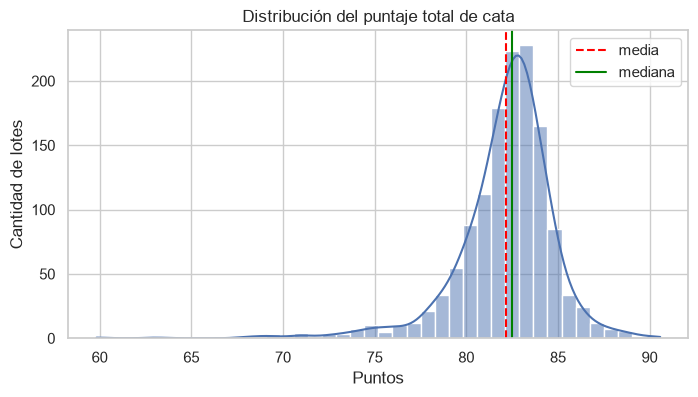

In [11]:
fig, ax = plt.subplots(figsize=(8, 4))
sns.histplot(df["total_cup_points"], bins=40, kde=True, ax=ax)
ax.axvline(df["total_cup_points"].mean(), color="red", ls="--", label="media")
ax.axvline(df["total_cup_points"].median(), color="green", ls="-", label="mediana")
ax.set(title="Distribución del puntaje total de cata", xlabel="Puntos", ylabel="Cantidad de lotes")
ax.legend()
plt.show()

> ✍️ **Interpretación:** ¿La distribución es simétrica? ¿Hacia qué lado está la cola? ¿Coincide con el signo de la asimetría calculada?
>
> _Escribí acá tu análisis._

### Gráfico 2 — Boxplots de los atributos sensoriales

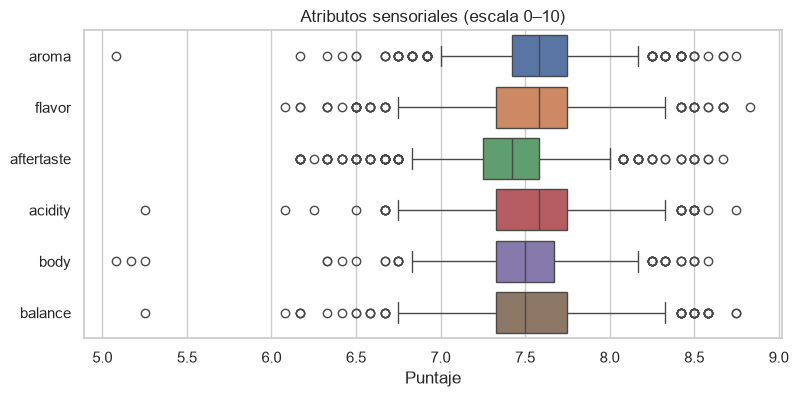

In [12]:
sensoriales = ["aroma", "flavor", "aftertaste", "acidity", "body", "balance"]
fig, ax = plt.subplots(figsize=(9, 4))
sns.boxplot(data=df[sensoriales], orient="h", ax=ax)
ax.set(title="Atributos sensoriales (escala 0–10)", xlabel="Puntaje")
plt.show()

### Gráfico 3 — Frecuencia de lotes por país (top 12)

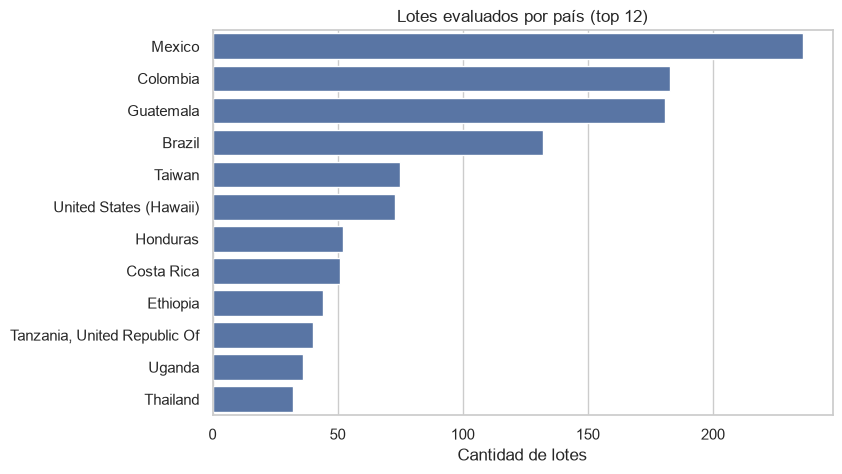

In [13]:
fig, ax = plt.subplots(figsize=(8, 5))
top = df["country_of_origin"].value_counts().head(12)
sns.barplot(x=top.values, y=top.index.astype(str), ax=ax, color="C0")
ax.set(title="Lotes evaluados por país (top 12)", xlabel="Cantidad de lotes", ylabel="")
plt.show()

## 6. Relaciones entre variables

### 6.1 Numérica – numérica: matriz de correlación

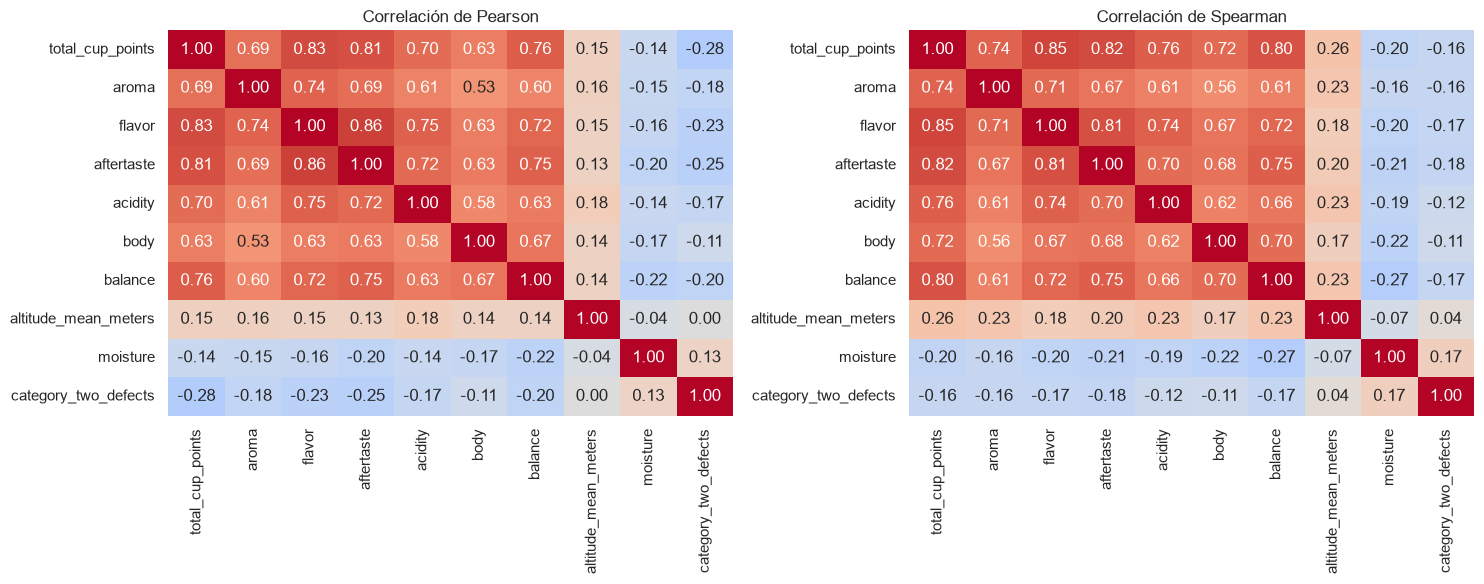

In [14]:
cols_corr = ["total_cup_points"] + sensoriales + ["altitude_mean_meters", "moisture", "category_two_defects"]
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
for ax, metodo in zip(axes, ["pearson", "spearman"]):
    sns.heatmap(df[cols_corr].corr(method=metodo), annot=True, fmt=".2f",
                cmap="coolwarm", vmin=-1, vmax=1, ax=ax, cbar=False)
    ax.set_title(f"Correlación de {metodo.capitalize()}")
plt.tight_layout()
plt.show()

In [15]:
# Correlación de cada variable con el puntaje total, con los tres métodos
corr_target = pd.DataFrame({
    m: df[cols_corr].corr(method=m)["total_cup_points"].drop("total_cup_points")
    for m in ["pearson", "spearman", "kendall"]
}).sort_values("spearman", ascending=False)
corr_target

,pearson,spearman,kendall
flavor,0.83,0.85,0.71
aftertaste,0.81,0.82,0.68
balance,0.76,0.80,0.66
acidity,0.70,0.76,0.60
aroma,0.69,0.74,0.58
body,0.63,0.72,0.56
altitude_mean_meters,0.15,0.26,0.18
category_two_defects,-0.28,-0.16,-0.12
moisture,-0.14,-0.20,-0.14


> ✍️ **Interpretación:** ¿Qué atributos se asocian más con el puntaje total? ¿Hay diferencias grandes entre Pearson y Spearman? ¿Qué sugiere eso sobre outliers o relaciones no lineales?
>
> _Escribí acá tu análisis._

### 6.2 Altitud vs. puntaje (scatter, con especie como tercera variable)

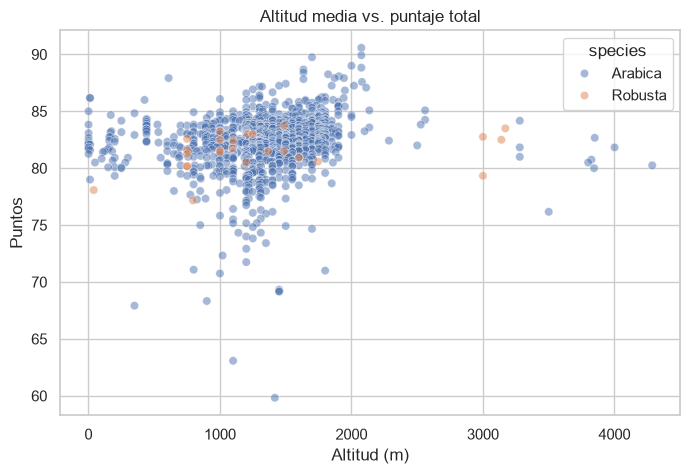

Pearson:  0.152
Spearman: 0.26


In [16]:
fig, ax = plt.subplots(figsize=(8, 5))
sns.scatterplot(data=df, x="altitude_mean_meters", y="total_cup_points",
                hue="species", alpha=0.5, ax=ax)
ax.set(title="Altitud media vs. puntaje total", xlabel="Altitud (m)", ylabel="Puntos")
plt.show()

alt = df[["altitude_mean_meters", "total_cup_points"]].dropna()
print("Pearson: ", round(alt.corr(method="pearson").iloc[0, 1], 3))
print("Spearman:", round(alt.corr(method="spearman").iloc[0, 1], 3))

> ✍️ **Interpretación:** ¿Hay relación entre altitud y calidad? ¿Es fuerte o débil? Recordá: correlación no implica causalidad.
>
> _Escribí acá tu análisis._

### 6.3 Numérica – categórica: puntaje por país (Centroamérica)

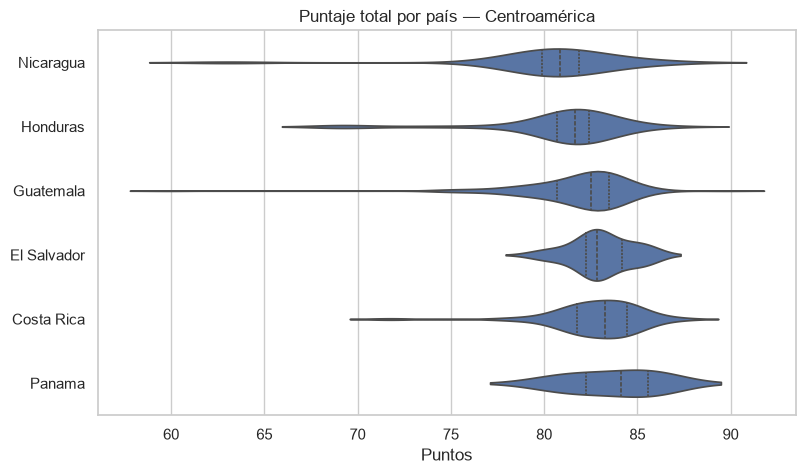

,count,mean,median,std
country_of_origin,,,,
Panama,4,83.71,84.12,2.41
Costa Rica,51,82.79,83.25,2.38
El Salvador,21,83.05,82.83,1.60
Guatemala,181,81.85,82.50,2.89
Honduras,52,80.88,81.67,3.56
Nicaragua,26,80.46,80.84,4.08


In [17]:
centroamerica = ["Honduras", "Guatemala", "Costa Rica", "El Salvador", "Nicaragua", "Panama"]
ca = df[df["country_of_origin"].isin(centroamerica)].copy()
ca["country_of_origin"] = ca["country_of_origin"].cat.remove_unused_categories()
orden = ca.groupby("country_of_origin", observed=True)["total_cup_points"].median().sort_values().index

fig, ax = plt.subplots(figsize=(9, 5))
sns.violinplot(data=ca, x="total_cup_points", y="country_of_origin", order=orden,
               inner="quartile", ax=ax)
ax.set(title="Puntaje total por país — Centroamérica", xlabel="Puntos", ylabel="")
plt.show()

ca.groupby("country_of_origin", observed=True)["total_cup_points"].agg(
    ["count", "mean", "median", "std"]
).sort_values("median", ascending=False)

> ✍️ **Interpretación:** ¿Dónde se ubica Honduras respecto a sus vecinos? Fijate en la cantidad de lotes (`count`): ¿qué tan confiable es la comparación con Panamá?
>
> _Escribí acá tu análisis._

### 6.4 Categórica – categórica: país vs. método de procesamiento

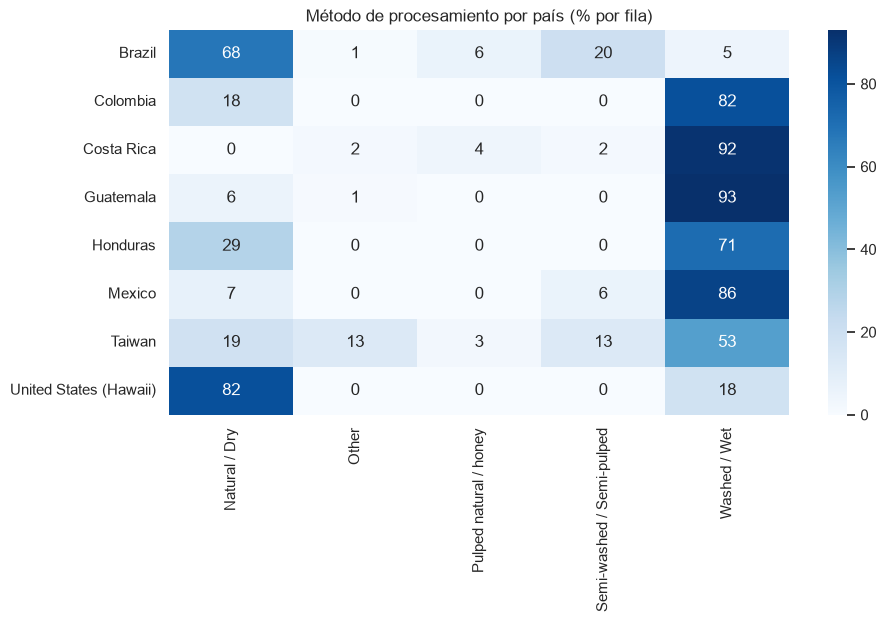

In [18]:
top_paises = df["country_of_origin"].value_counts().head(8).index
sub = df[df["country_of_origin"].isin(top_paises)]
tabla = pd.crosstab(sub["country_of_origin"].astype(str), sub["processing_method"].astype(str),
                    normalize="index") * 100

fig, ax = plt.subplots(figsize=(10, 5))
sns.heatmap(tabla, annot=True, fmt=".0f", cmap="Blues", ax=ax)
ax.set(title="Método de procesamiento por país (% por fila)", xlabel="", ylabel="")
plt.show()

> ✍️ **Interpretación:** ¿Hay países donde predomina claramente un método? ¿Qué país es la excepción?
>
> _Escribí acá tu análisis._

## 7. Conclusiones
Respondé brevemente cada pregunta guía con lo que encontraste:

1. **Distribución de la calidad:** …
2. **Atributos más asociados al puntaje:** …
3. **Altitud y calidad:** …
4. **Honduras vs. Centroamérica:** …
5. **Procesamiento y país:** …

### Limitaciones y próximos pasos
- Desbalance de especies (Arábica vs. Robusta) …
- Faltantes en altitud y procesamiento …
- Datos hasta 2018; los lotes los envían los productores (posible sesgo de selección) …